# BCSE331P – Exploratory Data Analysis
## Assessment 4: Bivariate Analysis
**Dataset:** `recid.csv` (1445 rows; columns: rownames, black, alcohol, drugs, super, married, felon, workprg, property, person, priors, educ, rules, age, tserved, follow, durat, cens, ldurat).

In [1]:
import pandas as pd, numpy as np, matplotlib.pyplot as plt, seaborn as sns
import warnings; warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
URL = "https://raw.githubusercontent.com/salemprakash/EDA/main/Data/recid.csv"

**Q1. Load the dataset**

In [2]:
df = pd.read_csv(URL)

In [3]:
# readable labels for the 0/1 coded columns (used for categorical analysis)
df["race"] = df["black"].map({1: "Black", 0: "Other"})
df["felon_status"] = df["felon"].map({1: "Felon", 0: "Non-felon"})
df["supervised"] = df["super"].map({1: "Supervised", 0: "Unsupervised"})
df["marital"] = df["married"].map({1: "Married", 0: "Single"})
df["offense"] = np.select([df["property"] == 1, df["person"] == 1], ["Property", "Person"], "Other")

In [4]:
num_vars = ["priors", "educ", "rules", "age", "tserved", "follow", "durat"]
df[["race", "felon_status", "supervised", "marital", "offense"] + num_vars].head()

,race,felon_status,supervised,marital,offense,priors,educ,rules,age,tserved,follow,durat
0,Other,Non-felon,Supervised,Married,Other,0,7,2,441,30,72,72
1,Black,Felon,Supervised,Single,Property,0,12,0,307,19,75,75
2,Other,Non-felon,Unsupervised,Single,Property,0,9,5,262,27,81,9
3,Other,Felon,Supervised,Single,Property,2,9,3,253,38,76,25
4,Other,Non-felon,Supervised,Single,Other,0,9,0,244,4,81,81


**Q2. Contingency table (`race` × `felon_status`) → stacked bar: Base plotting (matplotlib) and seaborn**

felon_status,Felon,Non-felon
race,,
Black,250,451
Other,204,540


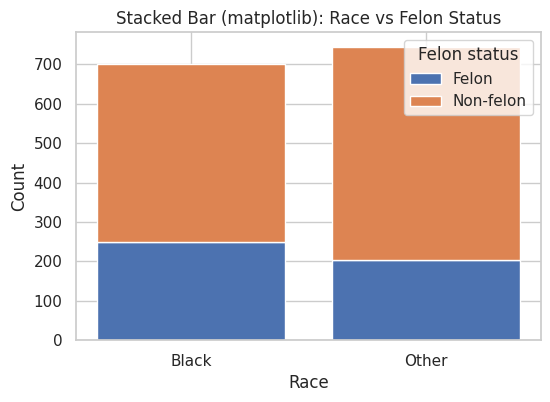

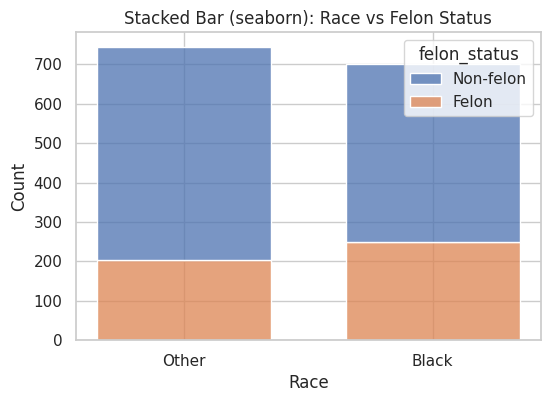

In [5]:
ct = pd.crosstab(df["race"], df["felon_status"]); display(ct)

# (a) simple stacked bar using base matplotlib
plt.figure(figsize=(6,4))
bottom = np.zeros(len(ct))
for col in ct.columns:
    plt.bar(ct.index, ct[col], bottom=bottom, label=col); bottom += ct[col].values
plt.title("Stacked Bar (matplotlib): Race vs Felon Status"); plt.xlabel("Race"); plt.ylabel("Count"); plt.legend(title="Felon status"); plt.show()

# (b) stacked bar using seaborn
plt.figure(figsize=(6,4))
sns.histplot(data=df, x="race", hue="felon_status", multiple="stack", shrink=.7)
plt.title("Stacked Bar (seaborn): Race vs Felon Status"); plt.xlabel("Race"); plt.ylabel("Count"); plt.show()

**Q3. Grouped / side-by-side bar plot (`offense` × `supervised`)**

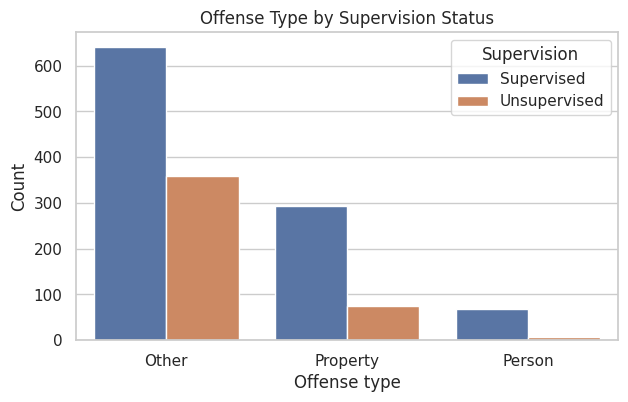

In [6]:
plt.figure(figsize=(7,4))
sns.countplot(data=df, x="offense", hue="supervised")
plt.title("Offense Type by Supervision Status"); plt.xlabel("Offense type"); plt.ylabel("Count"); plt.legend(title="Supervision"); plt.show()

**Q4. Scatter plot – `age` vs `tserved`**

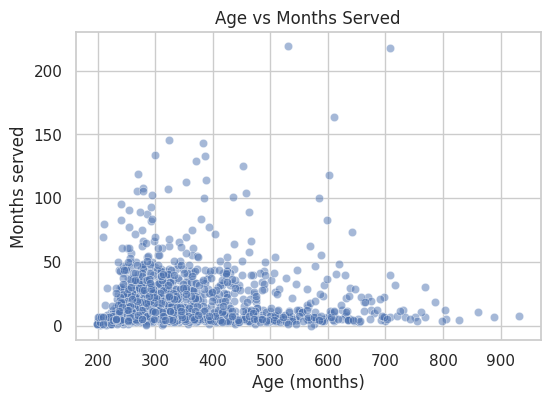

In [7]:
plt.figure(figsize=(6,4)); sns.scatterplot(data=df, x="age", y="tserved", alpha=.5)
plt.title("Age vs Months Served"); plt.xlabel("Age (months)"); plt.ylabel("Months served"); plt.show()

**Q5. Line plot – average `durat` by years of education**

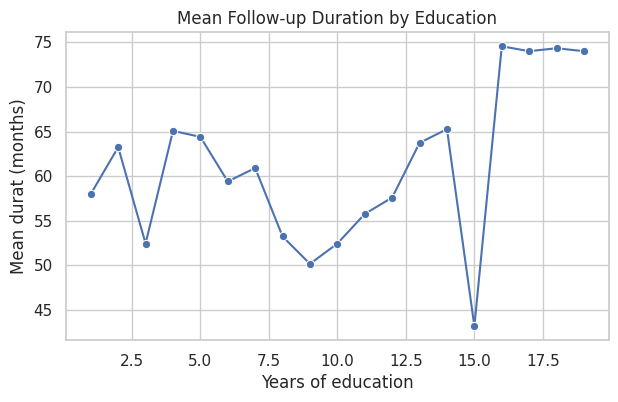

In [8]:
plt.figure(figsize=(7,4)); sns.lineplot(data=df, x="educ", y="durat", estimator="mean", errorbar=None, marker="o")
plt.title("Mean Follow-up Duration by Education"); plt.xlabel("Years of education"); plt.ylabel("Mean durat (months)"); plt.show()

**Q6. Heatmap of numerical variables**

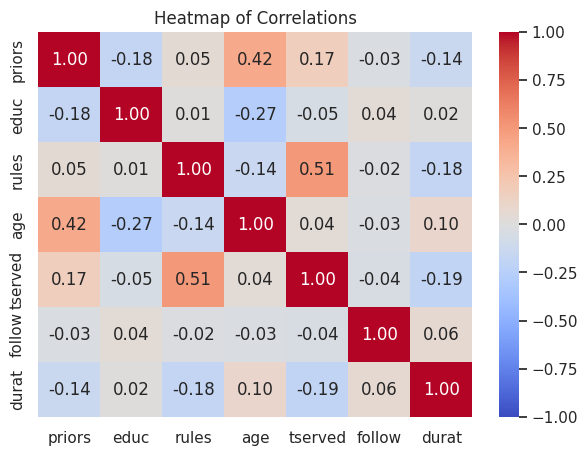

In [9]:
plt.figure(figsize=(7,5)); sns.heatmap(df[num_vars].corr(), annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Heatmap of Correlations"); plt.show()

**Q7. Bar chart comparing two variables** (mean `tserved` vs mean `durat` by race)

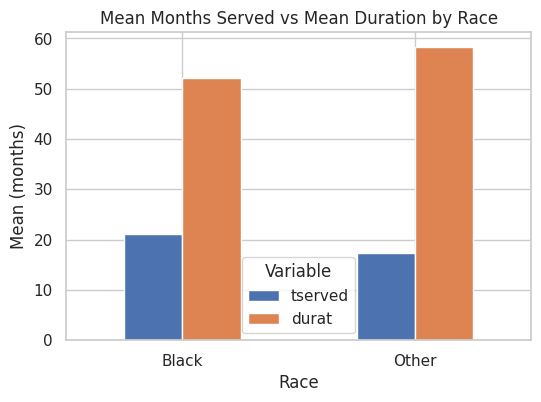

In [10]:
cmp = df.groupby("race")[["tserved", "durat"]].mean()
cmp.plot(kind="bar", rot=0, figsize=(6,4))
plt.title("Mean Months Served vs Mean Duration by Race"); plt.xlabel("Race"); plt.ylabel("Mean (months)"); plt.legend(title="Variable"); plt.show()

**Q8. Density plot – `age` across `race`**

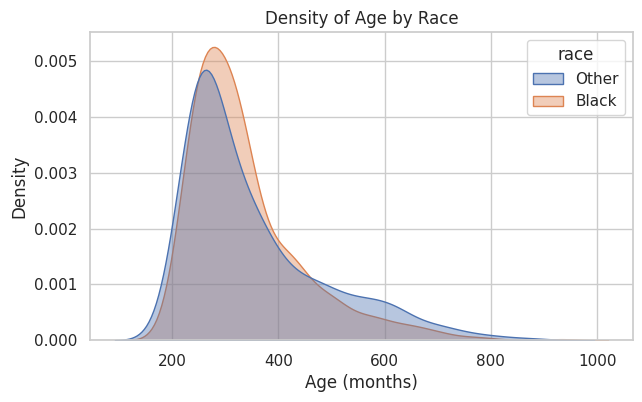

In [11]:
plt.figure(figsize=(7,4)); sns.kdeplot(data=df, x="age", hue="race", fill=True, common_norm=False, alpha=.4)
plt.title("Density of Age by Race"); plt.xlabel("Age (months)"); plt.show()

**Q9. Box plot – `tserved` across `offense`**

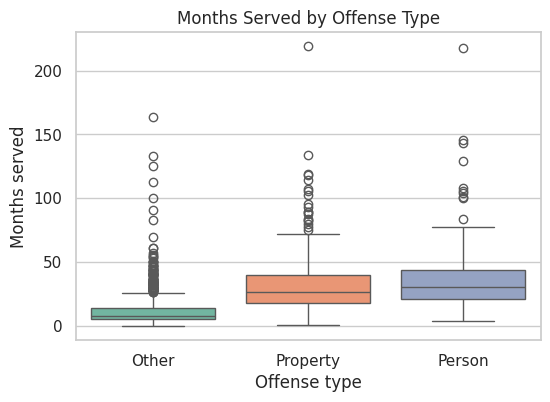

In [12]:
plt.figure(figsize=(6,4)); sns.boxplot(data=df, x="offense", y="tserved", palette="Set2")
plt.title("Months Served by Offense Type"); plt.xlabel("Offense type"); plt.ylabel("Months served"); plt.show()

**Q10. Violin plot – `tserved` across `offense`**

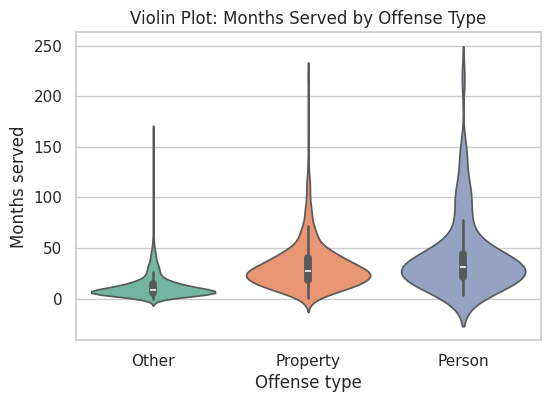

In [13]:
plt.figure(figsize=(6,4)); sns.violinplot(data=df, x="offense", y="tserved", palette="Set2")
plt.title("Violin Plot: Months Served by Offense Type"); plt.xlabel("Offense type"); plt.ylabel("Months served"); plt.show()

**Q11. Violin + box plot in one figure**

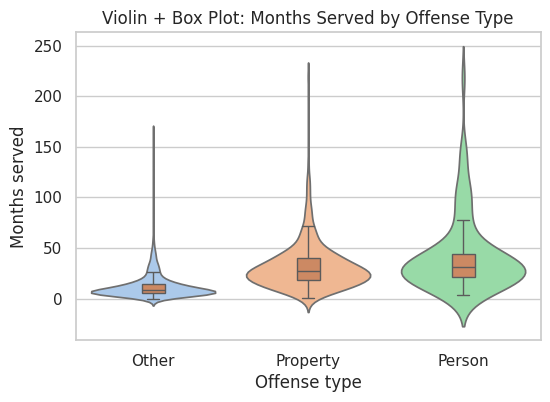

In [14]:
plt.figure(figsize=(6,4))
sns.violinplot(data=df, x="offense", y="tserved", inner=None, palette="pastel")
sns.boxplot(data=df, x="offense", y="tserved", width=.15, boxprops={"zorder": 2}, showfliers=False)
plt.title("Violin + Box Plot: Months Served by Offense Type"); plt.xlabel("Offense type"); plt.ylabel("Months served"); plt.show()

**Q12. Correlation matrix and correlogram**

,priors,educ,rules,age,tserved,follow,durat
priors,1.00,-0.18,0.05,0.42,0.17,-0.03,-0.14
educ,-0.18,1.00,0.01,-0.27,-0.05,0.04,0.02
rules,0.05,0.01,1.00,-0.14,0.51,-0.02,-0.18
age,0.42,-0.27,-0.14,1.00,0.04,-0.03,0.10
tserved,0.17,-0.05,0.51,0.04,1.00,-0.04,-0.19
follow,-0.03,0.04,-0.02,-0.03,-0.04,1.00,0.06
durat,-0.14,0.02,-0.18,0.10,-0.19,0.06,1.00


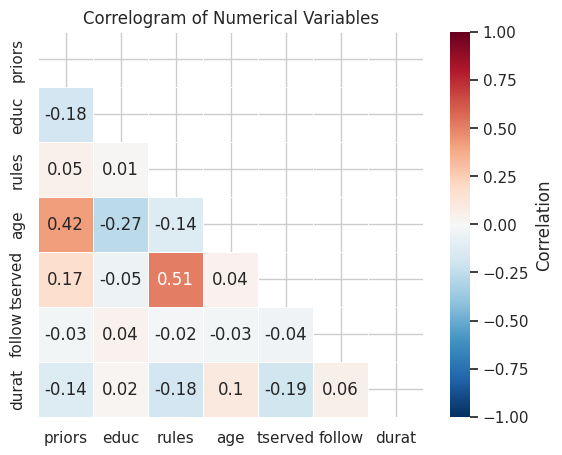

In [15]:
corr = df[num_vars].corr().round(2); display(corr)
mask = np.triu(np.ones_like(corr, dtype=bool))
plt.figure(figsize=(7,5))
sns.heatmap(corr, mask=mask, annot=True, cmap="RdBu_r", vmin=-1, vmax=1, square=True, linewidths=.5, cbar_kws={"label": "Correlation"})
plt.title("Correlogram of Numerical Variables"); plt.show()